# Initial audit: tenure and charges

**Practical Assignment 1 - partial team contribution**

We investigate three columns: `tenure`, `monthly_charges`, and `total_charges`.
This notebook identifies problems and provides evidence for later cleaning choices.
It has no model results yet. Imputation, clipping, transformations, and scaling
are still to be agreed and implemented after the baseline is established.

Data: the existing repository's `telecom_churn.csv`, associated with the team's
[Kaggle dataset](https://www.kaggle.com/datasets/amnaasabahat/telecom-churn/data).
See `TEAM_PLAN.md` for the proposed division of work.

**How to run:** launch Jupyter from the repository directory, then restart the
kernel and run all cells. We explore only training data. The held-out test data
is loaded by the shared splitter but is not profiled or used to choose rules.

In [1]:
from pathlib import Path
import platform

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scipy
import sklearn
from IPython.display import Markdown, display

from data_split import load_split, RANDOM_STATE, TEST_SIZE

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "font.size": 10})
NUMERIC = ["tenure", "monthly_charges", "total_charges"]
print({"Python": platform.python_version(), "pandas": pd.__version__,
       "numpy": np.__version__, "scipy": scipy.__version__,
       "sklearn": sklearn.__version__, "matplotlib": matplotlib.__version__})

{'Python': '3.11.5', 'pandas': '3.0.5', 'numpy': '2.4.6', 'scipy': '1.17.1', 'sklearn': '1.9.1', 'matplotlib': '3.11.2'}


## 1. Use the shared split

A row represents a customer record. Some customer IDs repeat, so a random
row-level split could put the same customer in training and testing. The shared
function stratifies **unique customers** by churn, holding out 20% of their IDs
with seed 42. It retains all rows, including duplicates, for this first audit.
The team still needs a consistent duplicate policy before fitting either model.

`churn = Yes` is the future model's positive class. `customer_id` is not a predictor.

In [2]:
train, test = load_split()
raw_numeric = train[NUMERIC].copy()
print(f"Seed: {RANDOM_STATE}; held-out fraction of customer IDs: {TEST_SIZE:.0%}")
print(f"Training: {len(train):,} rows / {train.customer_id.nunique():,} customers")
print(f"Held out: {len(test):,} rows / {test.customer_id.nunique():,} customers")
assert set(train.customer_id).isdisjoint(test.customer_id)
print(f"Exact duplicate rows within training: {train.duplicated().sum():,}")
print(f"Extra training records beyond unique IDs: {train.customer_id.duplicated().sum():,}")
display(train["churn"].value_counts().rename("training_rows").to_frame())
print("Churn class balance is descriptive here; no predictor/target associations are selected.")

Seed: 42; held-out fraction of customer IDs: 20%
Training: 16,025 rows / 16,000 customers
Held out: 4,005 rows / 4,000 customers
Exact duplicate rows within training: 17
Extra training records beyond unique IDs: 25


,training_rows
churn,
No,14750
Yes,1275


Churn class balance is descriptive here; no predictor/target associations are selected.


## 2. Distinguish missing values from formatting issues

We read every field as text and preserve empty fields. A blank is missing; a
value such as `$80.07 ` or `5,656` is a formatting issue and can still represent
a valid number. A naive numeric conversion would turn these into missing values.

The diagnostic parser below accepts plain signed decimals, and for charges only,
an optional leading dollar sign and correctly grouped thousands separators.
It rejects unknown tokens instead of silently guessing. It does not impute,
clip, drop rows, or overwrite the original CSV. This parsed view lets us inspect
the distributions; its use in a baseline or improved model remains a separate
documented choice. Units are inferred from the column names: tenure is a count
(likely months), while charges are monetary amounts. Confirm their definitions
before imposing hard business limits.

In [3]:
def parse_numeric(series, allow_currency=False):
    text = series.astype("string").str.strip()
    if allow_currency:
        text = text.str.replace(r"^\$\s*", "", regex=True)
        pattern = r"[+-]?(?:\d+|\d{1,3}(?:,\d{3})+)(?:\.\d+)?"
    else:
        pattern = r"[+-]?\d+(?:\.\d+)?"
    valid = text.str.fullmatch(pattern).fillna(False)
    accepted = text.where(valid).str.replace(",", "", regex=False)
    return pd.to_numeric(accepted, errors="coerce").astype(float)


numeric = pd.DataFrame(index=train.index)
quality_rows = []
format_examples = []
for col in NUMERIC:
    text = train[col].astype("string").str.strip()
    blank = text.eq("")
    strict = pd.to_numeric(text, errors="coerce")
    parsed = parse_numeric(train[col], allow_currency=(col != "tenure"))
    numeric[col] = parsed
    recovered = ~blank & strict.isna() & parsed.notna()
    unparsed = ~blank & parsed.isna()
    quality_rows.append({
        "variable": col,
        "training_rows": len(train),
        "blank_missing": int(blank.sum()),
        "blank_missing_pct": 100 * blank.mean(),
        "recovered_format_values": int(recovered.sum()),
        "unparsed_nonblank": int(unparsed.sum()),
        "numeric_available": int(parsed.notna().sum()),
    })
    for index in train.index[recovered][:3]:
        format_examples.append({"variable": col, "raw_text": repr(train.at[index, col]),
                                "parsed_value": parsed.at[index]})
    if unparsed.any():
        print(f"Investigate unknown tokens in {col}:")
        display(train.loc[unparsed, col].value_counts().head(10))

quality = pd.DataFrame(quality_rows).set_index("variable")
display(quality.round(3))
display(pd.DataFrame(format_examples))

,training_rows,blank_missing,blank_missing_pct,recovered_format_values,unparsed_nonblank,numeric_available
variable,,,,,,
tenure,16025,55,0.343,0,0,15970
monthly_charges,16025,1567,9.778,760,0,14458
total_charges,16025,506,3.158,390,0,15519


,variable,raw_text,parsed_value
0,monthly_charges,'$21.13 ',21.13
1,monthly_charges,'$73.40 ',73.40
2,monthly_charges,'$73.42 ',73.42
3,total_charges,"'1,724'",1724.00
4,total_charges,"'4,118'",4118.00
5,total_charges,"'6,412'",6412.00


## 3. Descriptive statistics and IQR flags

All statistics below use observed, parsed **training** values. Missing observations
are excluded from their calculation and are counted above. Standard deviation
uses the sample convention (`ddof=1`); kurtosis is excess kurtosis (a normal
distribution has 0). Range is maximum minus minimum.

IQR = Q3 - Q1. Values below Q1 - 1.5 IQR or above Q3 + 1.5 IQR are flagged for
review. A flag is evidence of an unusual value, not proof of a data entry error.
Negative values and noninteger tenure are separate checks that need interpretation.

In [4]:
summary_rows = []
for col in NUMERIC:
    values = numeric[col].dropna()
    q1, median, q3 = values.quantile([0.25, 0.50, 0.75])
    iqr = q3 - q1
    lower, upper = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    flags = values.lt(lower) | values.gt(upper)
    summary_rows.append({
        "variable": col, "n_observed": len(values),
        "mean": values.mean(), "median": median, "std_sample": values.std(ddof=1),
        "min": values.min(), "q1": q1, "q3": q3, "max": values.max(),
        "range": values.max() - values.min(), "skewness": values.skew(),
        "excess_kurtosis": values.kurt(), "iqr": iqr,
        "iqr_lower": lower, "iqr_upper": upper,
        "iqr_flagged": int(flags.sum()), "iqr_flagged_pct": 100 * flags.mean(),
        "negative_values": int(values.lt(0).sum()),
    })

summary = pd.DataFrame(summary_rows).set_index("variable")
display(summary.round(3).T)
observed_tenure = numeric.tenure.dropna()
print("Noninteger tenure values:", int((~np.isclose(observed_tenure % 1, 0)).sum()))

variable,tenure,monthly_charges,total_charges
n_observed,15970.000,14458.000,15519.000
mean,35.978,74.882,4045.163
median,36.000,69.925,4035.870
std_sample,22.362,59.737,2287.855
min,0.000,20.020,100.470
q1,17.000,44.952,2070.000
q3,53.000,95.008,6025.910
max,198.000,798.652,7999.030
range,198.000,778.632,7898.560
skewness,0.794,7.002,0.003


Noninteger tenure values: 0


## 4. See the distributions

Each row shows a histogram (frequency), boxplot (median, quartiles, and extremes),
and density estimate (a smoothed distribution). All observed values are included.
The dotted line marks the upper IQR fence. Tenure is a discrete count, so its
density curve is only a visual aid. KDE smoothing may extend beyond observed
values; that extension is not evidence of additional real observations.

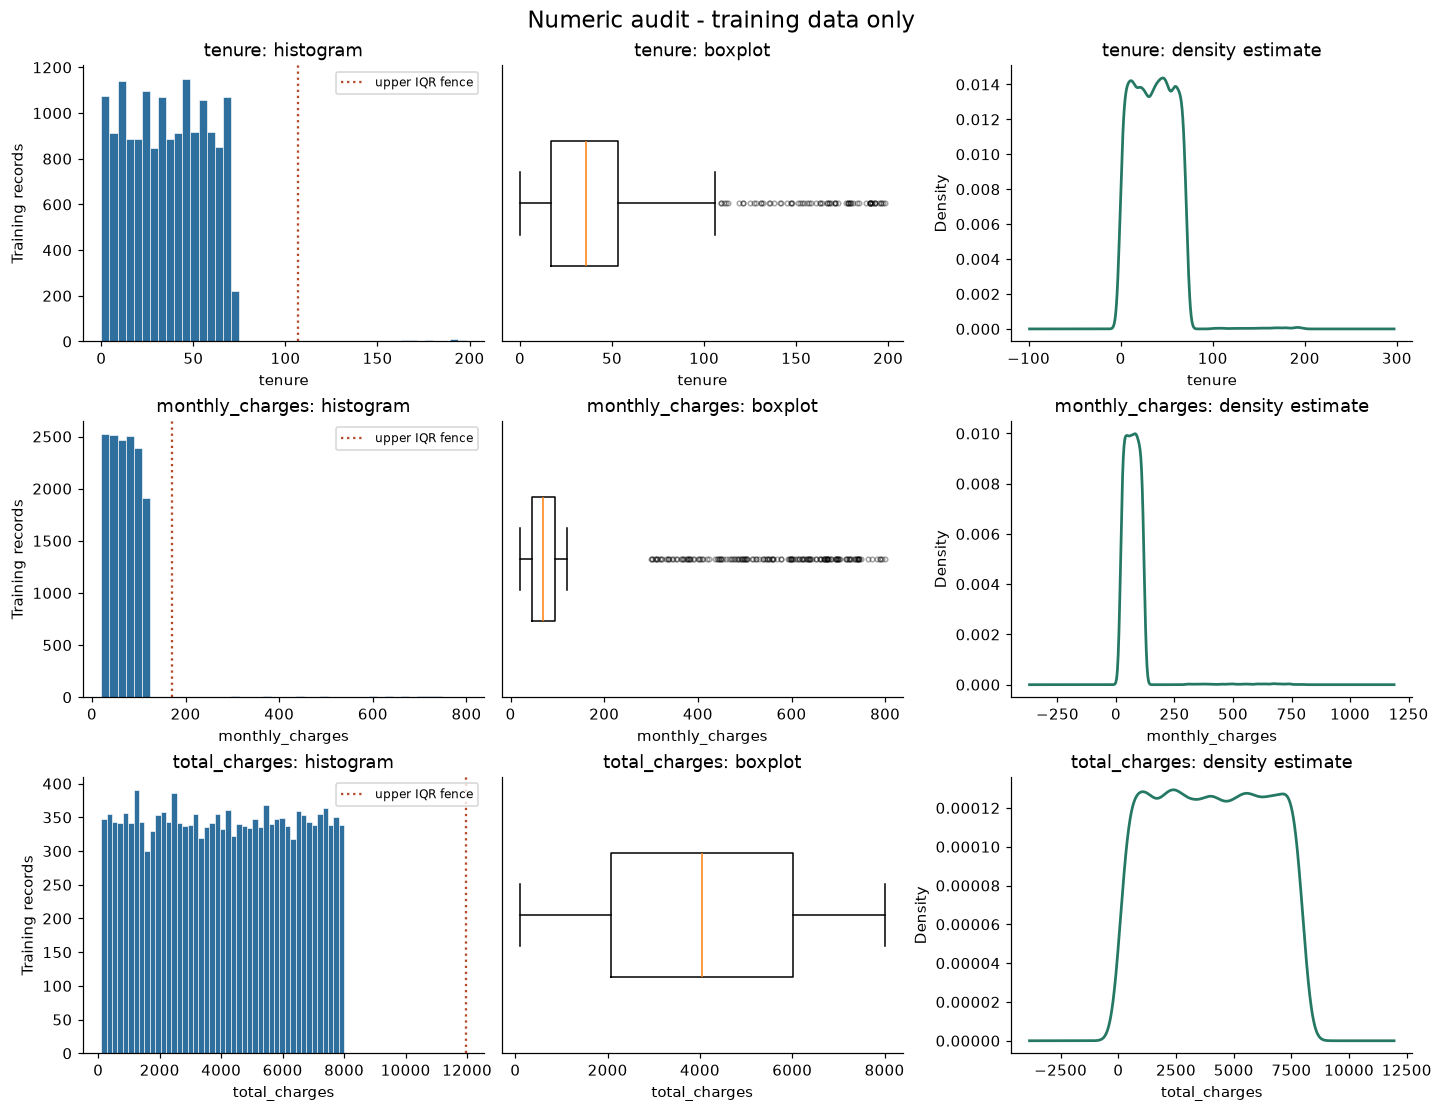

In [5]:
fig, axes = plt.subplots(3, 3, figsize=(13, 10), constrained_layout=True)
for row, col in enumerate(NUMERIC):
    values = numeric[col].dropna()
    fence = summary.at[col, "iqr_upper"]
    axes[row, 0].hist(values, bins=45, color="#2e6f9e", edgecolor="white", linewidth=0.4)
    axes[row, 0].axvline(fence, color="#b34a29", linestyle=":", label="upper IQR fence")
    axes[row, 0].set(title=f"{col}: histogram", xlabel=col, ylabel="Training records")
    axes[row, 0].legend(fontsize=8)
    axes[row, 1].boxplot(values, orientation="horizontal", widths=0.45,
                        flierprops={"markersize": 3, "alpha": 0.35})
    axes[row, 1].set(title=f"{col}: boxplot", xlabel=col, yticks=[])
    values.plot.kde(ax=axes[row, 2], color="#257864", lw=1.8)
    axes[row, 2].set(title=f"{col}: density estimate", xlabel=col, ylabel="Density")
fig.suptitle("Numeric audit - training data only", fontsize=15)
plt.show()

## 5. Turn the evidence into decisions

The largest observations below help quantify how far the tails extend.
They should be reviewed against data definitions before treatment.

In [6]:
display(pd.DataFrame({col: numeric[col].nlargest(5).to_numpy() for col in NUMERIC},
                     index=["largest", "2nd", "3rd", "4th", "5th"]))

for col in NUMERIC:
    missing = int(quality.at[col, "blank_missing"])
    recovered = int(quality.at[col, "recovered_format_values"])
    flagged = int(summary.at[col, "iqr_flagged"])
    skew = summary.at[col, "skewness"]
    display(Markdown(
        f"**{col}:** {missing:,} blank values; {recovered:,} formatted numbers recovered "
        f"for inspection; {flagged:,} observations outside the training IQR fences. "
        f"Mean = {summary.at[col, 'mean']:.2f}, median = {summary.at[col, 'median']:.2f}, "
        f"skewness = {skew:.3f}. "
        + ("Positive skewness indicates a longer right tail; compare the typical values "
           "with the extreme values before choosing a treatment."
           if skew > 0.5 else
           "The skewness alone does not give a strong reason to apply a log transformation.")
    ))

,tenure,monthly_charges,total_charges
largest,198.0,798.651621,7999.03
2nd,197.0,793.735520,7998.53
3rd,196.0,789.058345,7998.44
4th,196.0,788.229864,7998.16
5th,195.0,782.345595,7997.10


**tenure:** 55 blank values; 0 formatted numbers recovered for inspection; 69 observations outside the training IQR fences. Mean = 35.98, median = 36.00, skewness = 0.794. Positive skewness indicates a longer right tail; compare the typical values with the extreme values before choosing a treatment.

**monthly_charges:** 1,567 blank values; 760 formatted numbers recovered for inspection; 157 observations outside the training IQR fences. Mean = 74.88, median = 69.93, skewness = 7.002. Positive skewness indicates a longer right tail; compare the typical values with the extreme values before choosing a treatment.

**total_charges:** 506 blank values; 390 formatted numbers recovered for inspection; 0 observations outside the training IQR fences. Mean = 4045.16, median = 4035.87, skewness = 0.003. The skewness alone does not give a strong reason to apply a log transformation.

### Proposed next steps - not implemented model preprocessing

| Variable | Evidence to review | Candidate action and reason |
| --- | --- | --- |
| `tenure` | Blanks, integer check, maximum, and IQR flags | Verify the unit and legitimate upper range. Consider training-median imputation. Review extreme tenure before deciding whether to retain, mark missing, or cap it. |
| `monthly_charges` | Currency formatting, blanks, and high extremes | Normalize known currency formatting so valid amounts are not lost. Consider training-median imputation; compare retaining extremes with justified clipping within training validation. |
| `total_charges` | Grouped number formatting, blanks, and distribution shape | Parse valid thousands separators. Investigate why values are missing; consider training-median imputation. Try a transformation only if the distribution and validation support it. |

Do not invent missing values or outliers to make the assignment look more complete.
Do not assume `total_charges = tenure * monthly_charges` for this dataset, and do
not replace missing totals by zero without evidence. A histogram alone cannot
establish that a number is impossible.

For later logistic regression, train-fitted standard scaling is a candidate
because these variables have different units and ranges. Normal predictors are
not a requirement of logistic regression. Any learned imputation, scaling,
clipping, or transformation belongs in the training pipeline and must be applied
unchanged to validation/test data.

**Still to do:** agree on dataset suitability and the feature set; review duplicate
handling; establish the minimum-preprocessing baseline; implement and validate
cleaning; complete teammate analyses; refit and compare F1 and ROC-AUC; write the
combined notebook and PDF report. This notebook makes no claim of improved accuracy.

In [7]:
# Data invariants for this audit: the raw training values and row alignment survive.
pd.testing.assert_frame_equal(train[NUMERIC], raw_numeric)
assert numeric.index.equals(train.index)
for col in NUMERIC:
    assert quality.at[col, "blank_missing"] + quality.at[col, "unparsed_nonblank"] + quality.at[col, "numeric_available"] == len(train)
print("Audit checks passed: raw values preserved, row indices aligned, counts reconciled.")

Audit checks passed: raw values preserved, row indices aligned, counts reconciled.
